# Structural comparison of chemical label-graph variants

This notebook enumerates every combination of taxonomies and structural options of the chemical label graph and measures, for each realized graph, how many ions it labels, how many trainable class labels it provides, how redundant and hub-dominated it is, and how quickly graph propagation makes ion representations indistinguishable. It answers which graph structure is a sensible input for a graph network generating classifier weights (ML-GCN / R-GCN), independently of the final autoencoder architecture.

## Introduction

The label graph $G=(V_M\cup V_C, E, R)$ has ion nodes $V_M$ (`formula|adduct`) and class nodes $V_C$; relations $R$ are `belongs_to` (ion → class), `is_a` (class → nearest retained parent class), `equivalent_to` (class ↔ class of another taxonomy declared by ChemOnt synonyms) and `same_formula` (ion ↔ ion of the same neutral formula). In ML-GCN-type architectures a graph network maps node features $H^{(0)}$ to node embeddings $E=\mathrm{GCN}(G, H^{(0)})$ whose rows become classifier weight vectors of the molecule and class heads; the encoder is unchanged and the graph acts only through these weights. The structure of $G$ therefore determines which classifiers share parameters.

A variant is defined by:

| axis | values | meaning |
|---|---|---|
| taxonomies | all 15 non-empty subsets of {LM, SL, CF, ChEBI} | which class nodes exist |
| resolution | `metaspace_ids`, `formula` | candidate structures of an ion |
| assignment | `certain`, `possible`, `weighted` | intersection, union, or candidate support fraction |
| attachment | `most_specific`, `all_ancestors` | ion connects to its deepest classes only, or to its whole closure |
| alignment | `none`, `exact`, `declared` | cross-taxonomy class edges (only for combinations with ClassyFire) |
| adduct links | `0`, `1` | `same_formula` edges between adducts of one formula |
| pruning | `none`, `informative` | remove classes with < 2 ions or covering > 50 % of the resolved ions of their taxonomy |

### Assumptions

- **Fixed ion node set.** Every variant contains all ions of the collection; unresolved ions are isolated nodes. Coverage differences are therefore visible and not hidden by changing denominators.
- **Symmetrized propagation.** Over-smoothing is measured with the symmetric normalized adjacency $\hat A = D^{-1/2}(A+I)D^{-1/2}$ of all relations, i.e. a linear GCN without learned weights. A relational GCN with relation-specific weights can counteract part of the mixing; the statistic measures the receptive field the architecture would start from.
- **Pruning thresholds** (2 ions, 50 %) are fixed in `analysis_settings.yaml`; they are heuristics, not optimized.

### Notation

- $W \in [0,1]^{|V_M|\times|V_C|}$ — ion-to-class closure membership weights of a variant.
- Coverage — fraction of ions with at least one class; trainable labels — classes with at least 5 ions.
- Max class fraction — largest class support divided by the number of resolved ions (hub dominance).
- Redundant class fraction — share of classes whose ion set equals that of another class (e.g. single-child chains).
- $\bar\kappa_k$ — mean pairwise cosine similarity of resolved ions' rows of $\hat A^k$ (over-smoothing after $k$ propagation steps; 0 = orthogonal, 1 = identical receptive fields).

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "graph_variants"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:55:54,401 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:55:54,404 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:55:54,809 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:55:54,810 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:55:54,818 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:55:54,819 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:55:54,837 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:55:54,851 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:55:54,853 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis graph_variants


## Coverage and label richness of taxonomy combinations

### Methodology

#### Theoretical

Coverage measures how many ions can be supervised through classes, the number of trainable labels measures how many class outputs a chemical-class head would have, and the max class fraction measures whether one class dominates. A useful graph has high coverage, a moderate number of trainable labels and no class containing almost every ion.

#### Implementation

Metrics come from `variant_metrics.csv`; the remaining axes are fixed by the knobs of the cell so that only the taxonomy combination varies.

#### Figure descriptions

*Figure 1.* Each point is one taxonomy combination for the fixed remaining axes; $x$: coverage, $y$: trainable labels (logarithmic); colour: taxonomy (single) or grey shade by number of combined taxonomies; marker size: max class fraction. Left panel: kidney; right panel: brain. Points toward the upper right label more ions with more classes.

coverage  class_count  trainable_labels  max_class_fraction  redundant_class_fraction  classes_per_ion_mean  co_class_pair_fraction
collection taxonomy_label                                                                                                                                     
kidney     LM                 0.443           60                31               0.427                     0.083                 2.026                   0.311
           SL                 0.310           53                30               0.157                     0.151                 2.318                   0.113
           CF                 0.470          113                48               0.563                     0.177                 2.877                   0.354
           ChEBI              0.592          271               149               0.722                     0.410                13.457                   0.796
           LM+SL              0.542          113                61               0.349                     0.124                 2.983                   0.228
           LM+CF              0.705          173                79               0.375                     0.150                 3.189                   0.257
           LM+ChEBI           0.752          331               180               0.568                     0.356                11.785                   0.557
           SL+CF              0.659          166                78               0.401                     0.181                 3.141                   0.200
           SL+ChEBI           0.709          324               179               0.602                     0.367                12.245                   0.566
           CF+ChEBI           0.754          384               197               0.566                     0.346                12.351                   0.581
           LM+SL+CF           0.777          226               109               0.340                     0.164                 3.818                   0.219
           LM+SL+ChEBI        0.827          384               210               0.516                     0.331                11.579                   0.467
           LM+CF+ChEBI        0.841          444               228               0.508                     0.318                12.141                   0.508
           SL+CF+ChEBI        0.841          437               227               0.508                     0.327                11.927                   0.474
           LM+SL+CF+ChEBI     0.904          497               258               0.472                     0.306                12.094                   0.445
brain      LM                 0.509           69                38               0.165                     0.072                 1.915                   0.105
           SL                 0.434           55                38               0.209                     0.127                 2.245                   0.124
           CF                 0.493          117                51               0.487                     0.171                 2.581                   0.264
           ChEBI              0.582          307               163               0.709                     0.443                17.099                   0.795
           LM+SL              0.622          124                76               0.146                     0.113                 3.133                   0.094
           LM+CF              0.771          186                89               0.311                     0.140                 2.915                   0.145
           LM+ChEBI           0.744          376               201               0.554                     0.380                14.673                   0.513
           SL+CF              0.746          172                89               0.322                     0.157                 3.013                   0.148
           SL+ChEBI           0.721          362    

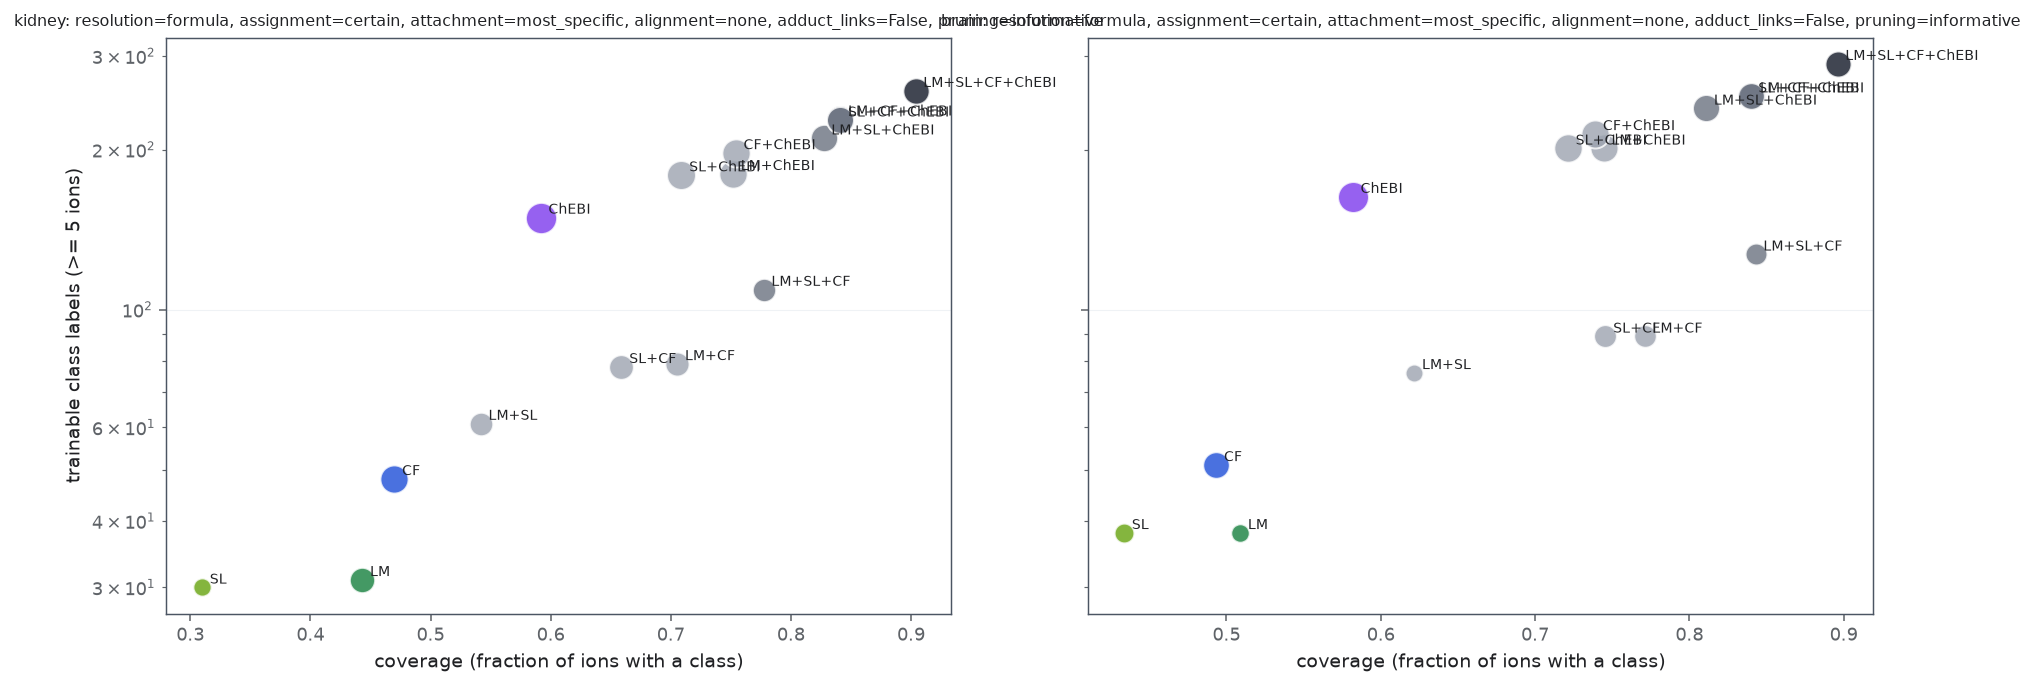

In [2]:
metrics = table("variant_metrics.csv")
metrics["adduct_links"] = metrics.adduct_links.astype(bool)

# --- what this figure shows -------------------------------------------------
FIXED = {"resolution": "formula", "assignment": "certain", "attachment": "most_specific",
         "alignment": "none", "adduct_links": False, "pruning": "informative"}
# ---------------------------------------------------------------------------
mask = np.logical_and.reduce([metrics[k] == v for k, v in FIXED.items()])
subset = metrics[mask]
figure, axes = plt.subplots(1, len(COLLECTIONS), figsize=(7 * len(COLLECTIONS), 5), sharey=True)
for axis, collection in zip(np.atleast_1d(axes), COLLECTIONS):
    rows = subset[subset.collection == collection]
    for record in rows.itertuples():
        axis.scatter(record.coverage, record.trainable_labels, s=40 + 300 * record.max_class_fraction,
                     color=plots.taxonomy_color(record.taxonomy_label), alpha=0.8, edgecolor="white")
        axis.annotate(record.taxonomy_label, (record.coverage, record.trainable_labels), fontsize=7,
                      xytext=(4, 2), textcoords="offset points")
    axis.set_yscale("log")
    axis.set_xlabel("coverage (fraction of ions with a class)")
    axis.set_title(f"{collection}: " + ", ".join(f"{k}={v}" for k, v in FIXED.items()), fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("trainable class labels (>= 5 ions)")
plt.tight_layout()
display(subset.set_index(["collection", "taxonomy_label"])[["coverage", "class_count", "trainable_labels",
        "max_class_fraction", "redundant_class_fraction", "classes_per_ion_mean", "co_class_pair_fraction"]].round(3))

### Remarks

- With `certain` assignment, most-specific attachment and informative pruning, single taxonomies label 31–59 % (kidney) / 43–58 % (brain) of ions; LM+CF reaches 71 % / 77 % and all four taxonomies 90 %.
- ChEBI dominates every combination containing it: 13–17 classes per ion, 41–44 % redundant classes and a co-class pair fraction of ≈ 0.80 (almost every ion pair shares a class even after pruning). LIPID MAPS and SwissLipids give ≈ 2 classes per ion with co-class fractions 0.10–0.31.
- `max_class_fraction` can exceed the 0.5 pruning threshold because pruning is applied per taxonomy before ions without retained classes drop out of the denominator.

### Notes

## Effect of each structural axis

### Methodology

#### Theoretical

For a structural axis (assignment, attachment, alignment, adduct links, pruning, resolution), the distribution of a metric over all variants sharing an axis value shows the effect of that axis marginalized over the other choices. Differences between violins show which decisions change the graph materially and which are nearly irrelevant.

#### Implementation

All variants of `variant_metrics.csv` for the selected collection are grouped by the selected axis. Alignment values other than `none` exist only for combinations containing ClassyFire, so their violins contain fewer variants.

#### Figure descriptions

*Figure 2.* One panel per metric; $x$: values of the selected axis; $y$: metric value; each point is one variant (all other axes vary within a violin). The horizontal line is the median over all variants.

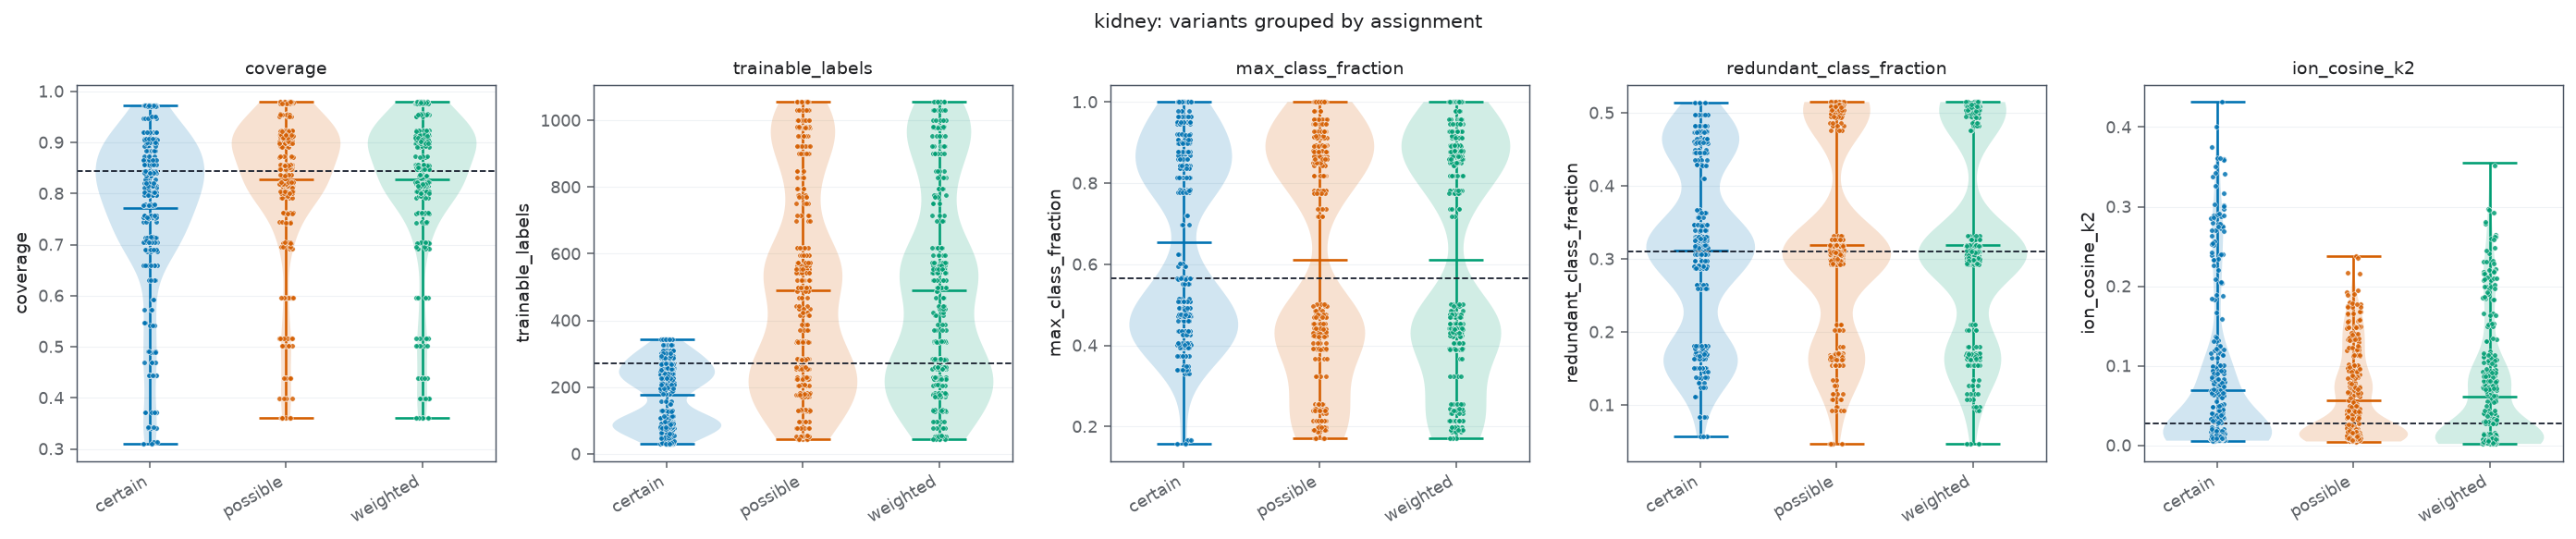

In [3]:
# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
AXIS = "assignment"        # resolution | assignment | attachment | alignment | adduct_links | pruning
METRICS = ["coverage", "trainable_labels", "max_class_fraction", "redundant_class_fraction", "ion_cosine_k2"]
# ---------------------------------------------------------------------------
subset = metrics[metrics.collection == COLLECTION].assign(group=lambda f: f[AXIS].astype(str))
order = sorted(subset.group.unique())
figure, axes = plt.subplots(1, len(METRICS), figsize=(4 * len(METRICS), 4.2))
for axis, metric in zip(axes, METRICS):
    plots.violin_groups(axis, subset, group="group", value=metric, order=order,
                        reference=float(subset[metric].median()), theme=THEME)
    axis.set_title(metric, fontsize=10)
figure.suptitle(f"{COLLECTION}: variants grouped by {AXIS}", fontsize=11)
plt.tight_layout()

### Remarks

- `certain` halves the number of trainable labels relative to `possible`/`weighted` (median 194 vs 455 over all kidney variants) and lowers coverage only slightly (0.81 vs 0.86); `possible` and `weighted` produce identical structural statistics because they share the same class sets and differ only in edge weights.
- `formula` resolution increases median coverage from 0.81 to 0.90. Alignment and adduct links change no structural statistic materially (median `ion_cosine_k2` 0.025–0.028); their effect is limited to a few dozen edges (473 `equivalent_to` edges for all four taxonomies with `declared`).

### Notes

## Over-smoothing of ion representations under graph propagation

### Methodology

#### Theoretical

With one-hot initial features, row $m$ of $\hat A^k$ is the receptive field of ion $m$ after $k$ propagation steps. If $\bar\kappa_k$ approaches 1, classifier weights generated by a $k$-layer GCN cannot distinguish ions any more (over-smoothing); ML-GCN reported degradation beyond two layers. Hub classes (high max class fraction) and attachment to all ancestors accelerate smoothing, because every ion is directly connected to the same general classes.

#### Implementation

$\bar\kappa_k$ is computed for $k\in\{1,2,3\}$ with $\sum_{i\neq j} u_i^\top u_j = \lVert\sum_i u_i\rVert^2 - n$ over unit rows $u_i$ of resolved ions, on the GPU (sparse-dense products).

#### Figure descriptions

*Figure 3.* $x$: propagation depth $k$; $y$: $\bar\kappa_k$; one line per variant of the selected taxonomy combinations, colour = taxonomy combination, line style = attachment (solid: most specific, dashed: all ancestors); other axes fixed by the knobs. Lower curves keep ions distinguishable for deeper GCNs.

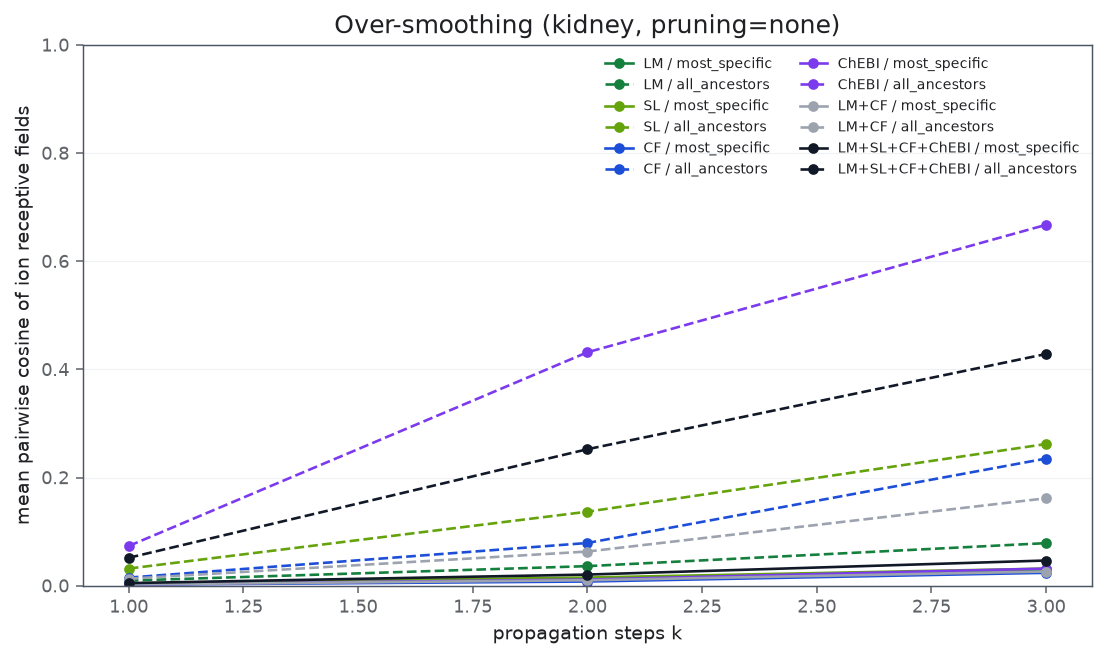

In [4]:
# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
COMBINATIONS = ["LM", "SL", "CF", "ChEBI", "LM+CF", "LM+SL+CF+ChEBI"]
FIXED = {"resolution": "formula", "assignment": "certain", "alignment": "none", "adduct_links": False}
PRUNING = "none"
# ---------------------------------------------------------------------------
mask = np.logical_and.reduce([metrics[k] == v for k, v in FIXED.items()])
subset = metrics[mask & (metrics.collection == COLLECTION) & (metrics.pruning == PRUNING)
                 & metrics.taxonomy_label.isin(COMBINATIONS)]
steps = [c for c in metrics.columns if c.startswith("ion_cosine_k")]
figure, axis = plt.subplots(figsize=(8, 4.8))
for record in subset.itertuples():
    values = [getattr(record, c) for c in steps]
    axis.plot([int(c[-1]) for c in steps], values, marker="o", color=plots.taxonomy_color(record.taxonomy_label),
              linestyle="-" if record.attachment == "most_specific" else "--",
              label=f"{record.taxonomy_label} / {record.attachment}")
axis.set_xlabel("propagation steps k")
axis.set_ylabel("mean pairwise cosine of ion receptive fields")
axis.set_ylim(0, 1)
axis.legend(fontsize=7, frameon=False, ncols=2)
axis.set_title(f"Over-smoothing ({COLLECTION}, pruning={PRUNING})")
plt.tight_layout()

### Remarks

- Attachment controls over-smoothing: median $\bar\kappa_2$ is 0.010 with most-specific attachment and 0.089 with all-ancestor attachment; ChEBI with all ancestors reaches 0.43 at $k=2$ and 0.67 at $k=3$. With most-specific attachment every shown combination stays below 0.05 up to $k=3$.

### Notes

## Visual structure of focus graphs

### Methodology

#### Theoretical

A subgraph around one chemical class shows concretely what the relations of a variant look like: which classes an ion is attached to, how deep the hierarchy above it is, where taxonomies are linked, and how ambiguous ions are attached to coarser classes than unambiguous ones.

#### Implementation

For the selected focus variant, ions with a `belongs_to` edge to a class whose name contains the query are selected (at most `MAX_IONS`, ordered by recurrence across images). The subgraph contains these ions, all classes they are attached to, all `is_a` ancestors of those classes within the graph and the `equivalent_to`/`same_formula` edges among included nodes. Nodes and edges come from `focus_graph_nodes.csv` and `focus_graph_edges.csv`.

#### Figure descriptions

*Figure 4.* Layered drawing: ions (grey) on the bottom row; classes above them by depth with roots on top; class colour = taxonomy; class marker size grows with the number of ions in the class. Thin solid edges: `belongs_to`; thick edges: `is_a`; dashed: `equivalent_to`; dotted: `same_formula`. Horizontal positions are barycentric and carry no quantitative meaning.

CF/formula/certain/all_ancestors/align=none/adduct=0/prune=informative
CF/formula/certain/all_ancestors/align=none/adduct=0/prune=none
CF/formula/weighted/all_ancestors/align=none/adduct=0/prune=none
CF/metaspace_ids/certain/all_ancestors/align=none/adduct=0/prune=none
ChEBI/formula/certain/all_ancestors/align=none/adduct=0/prune=none
LM+CF/formula/certain/all_ancestors/align=declared/adduct=0/prune=none
LM+SL+CF+ChEBI/formula/certain/all_ancestors/align=declared/adduct=0/prune=informative
LM/formula/certain/all_ancestors/align=none/adduct=0/prune=none
SL/formula/certain/all_ancestors/align=none/adduct=0/prune=none


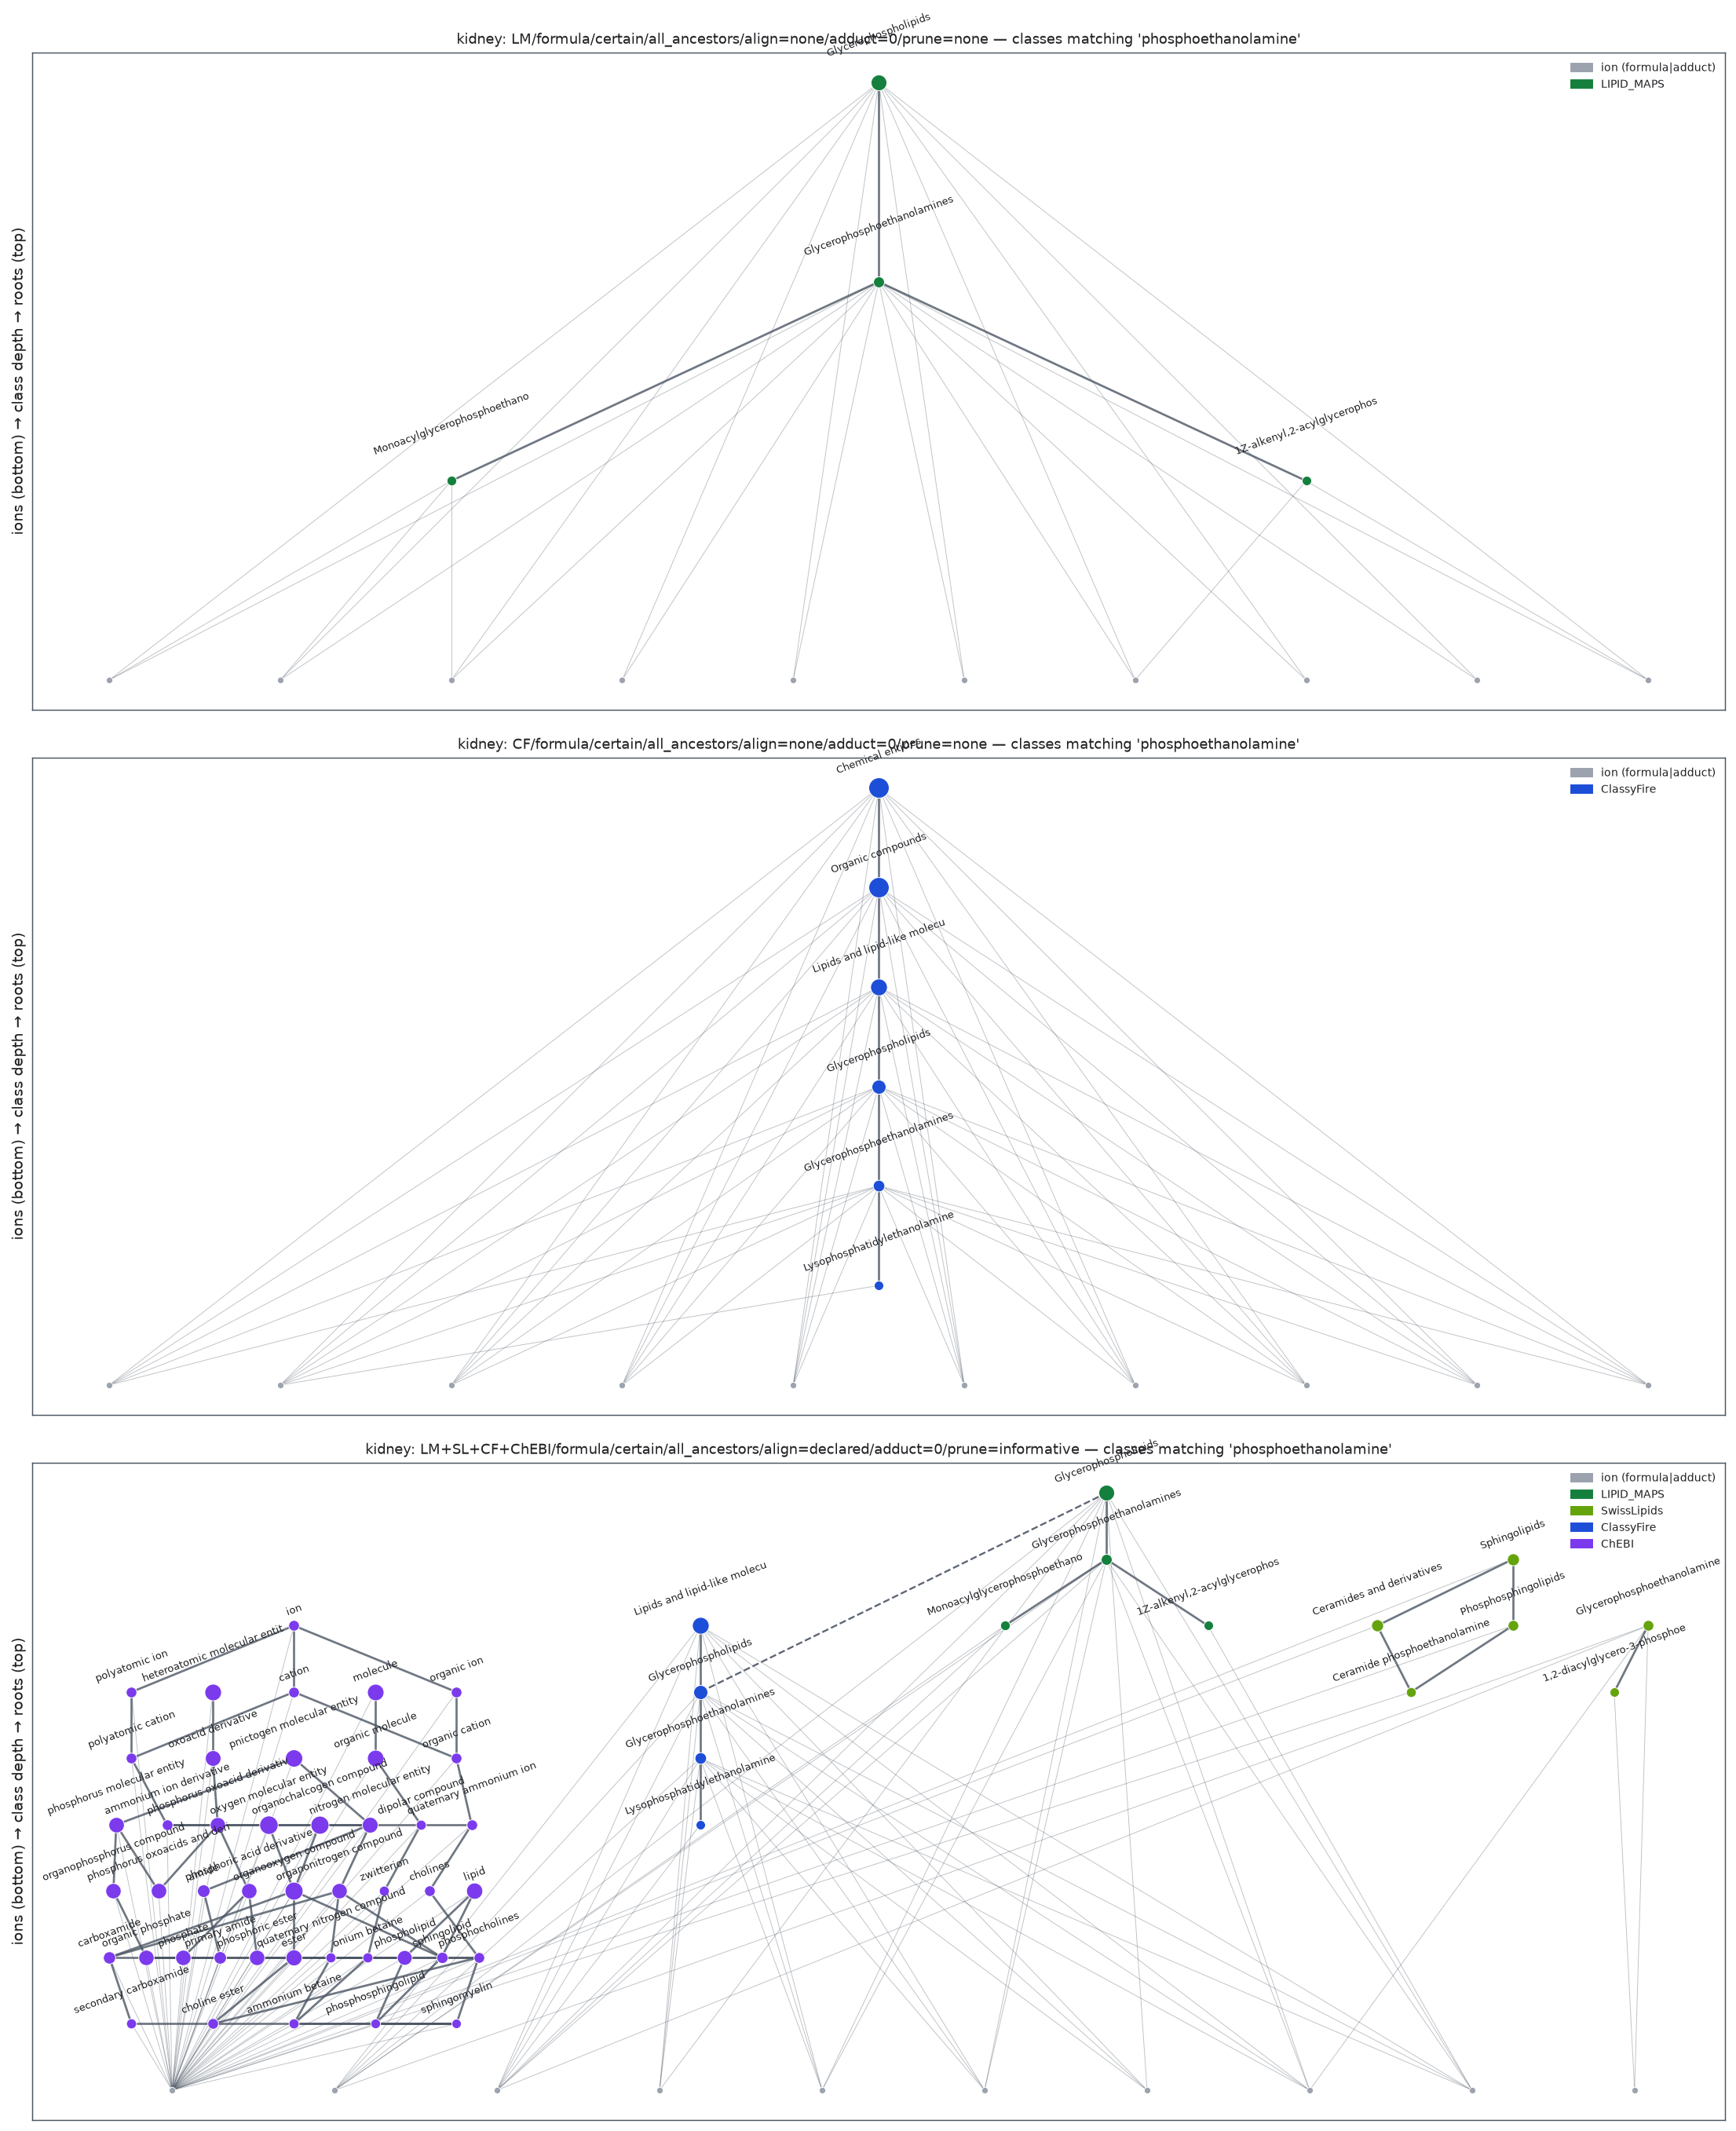

In [5]:
nodes = table("focus_graph_nodes.csv")
edges = table("focus_graph_edges.csv")
print("\n".join(sorted(nodes.variant_id.unique())))

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
VARIANTS = ["LM/formula/certain/all_ancestors/align=none/adduct=0/prune=none",
            "CF/formula/certain/all_ancestors/align=none/adduct=0/prune=none",
            "LM+SL+CF+ChEBI/formula/certain/all_ancestors/align=declared/adduct=0/prune=informative"]
CLASS_QUERY = "phosphoethanolamine"     # case-insensitive substring of a class name
MAX_IONS = 10
# ---------------------------------------------------------------------------


def subgraph(variant):
    variant_nodes = nodes[(nodes.collection == COLLECTION) & (nodes.variant_id == variant)]
    variant_edges = edges[(edges.collection == COLLECTION) & (edges.variant_id == variant)]
    classes = variant_nodes[(variant_nodes.node_type == "class") & variant_nodes.name.str.contains(CLASS_QUERY, case=False, na=False)]
    belongs = variant_edges[variant_edges.relation == "belongs_to"]
    ions = belongs[belongs.target.isin(classes.node_id)].source.unique()
    ions = variant_nodes[variant_nodes.node_id.isin(ions)].nlargest(MAX_IONS, "dataset_count").node_id
    keep = set(ions) | set(belongs[belongs.source.isin(ions)].target)
    is_a = variant_edges[variant_edges.relation == "is_a"]
    frontier = set(keep)
    while frontier:
        parents = set(is_a[is_a.source.isin(frontier)].target) - keep
        keep |= parents
        frontier = parents
    selected_edges = variant_edges[variant_edges.source.isin(keep) & variant_edges.target.isin(keep)]
    return variant_nodes[variant_nodes.node_id.isin(keep)], selected_edges


figure, axes = plt.subplots(len(VARIANTS), 1, figsize=(16, 6.5 * len(VARIANTS)))
for axis, variant in zip(np.atleast_1d(axes), VARIANTS):
    sub_nodes, sub_edges = subgraph(variant)
    plots.draw_label_graph(axis, sub_nodes, sub_edges, theme=THEME)
    axis.set_title(f"{COLLECTION}: {variant} — classes matching '{CLASS_QUERY}'", fontsize=9)
plt.tight_layout()

### Remarks

- In the combined graph the declared ChemOnt synonym appears as a single dashed `equivalent_to` edge between LIPID MAPS *Glycerophospholipids* and ClassyFire *Glycerophospholipids*; ChEBI contributes most nodes (generic classes such as *organic molecular entity*, *ion*, *zwitterion*), which illustrates its redundancy.

### Notes

## Results / Summary

### LLM

**Observed.** Over 1392 variants per collection, the taxonomy combination determines coverage (single lipid taxonomies 31–51 %, all four 90 % of ions with `certain` labels), `certain` assignment halves the label count relative to `possible`, and the attachment rule is the main driver of over-smoothing (median mean cosine of receptive fields at $k=2$: 0.010 most-specific vs 0.089 all ancestors). ChEBI adds many redundant, near-universal classes. Alignment and adduct links have negligible structural effect.

**Interpretation for the graph design.** A defensible label graph for ML-GCN/R-GCN is: `formula` resolution, `certain` assignment (or `weighted` if soft labels are wanted), attachment of ions to their most specific classes with hierarchy carried by `is_a` edges, informative pruning, and a lipid taxonomy (LIPID MAPS or SwissLipids — nearly identical partitions, part 0.2) combined with ClassyFire for non-lipid coverage. ChEBI is not recommended as a class source: it inflates labels and over-smooths without adding structure that the other taxonomies lack. Two to three propagation layers are structurally safe under most-specific attachment.

**Caveats.** The statistics are structural; whether the relations are biologically meaningful for MSI is tested in parts 3 and 4. The pruning thresholds are heuristics.

### Person